In [148]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

In [149]:
from sklearn.datasets import load_breast_cancer  # Example dataset

In [150]:
data=load_breast_cancer()
X,y=data.data,data.target

In [151]:
# 2. PCA to reduce to 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [152]:
X_train,X_test,y_train,y_test = train_test_split(X_pca,y,test_size=0.2,random_state=42)

In [153]:
model=AdaBoostClassifier(estimator=None)
model.fit(X_train,y_train)

AdaBoostClassifier()

In [154]:
y_pred=model.predict(X_test)
accuracy=accuracy_score(y_test,y_pred)

In [155]:
print(accuracy)

0.956140350877193


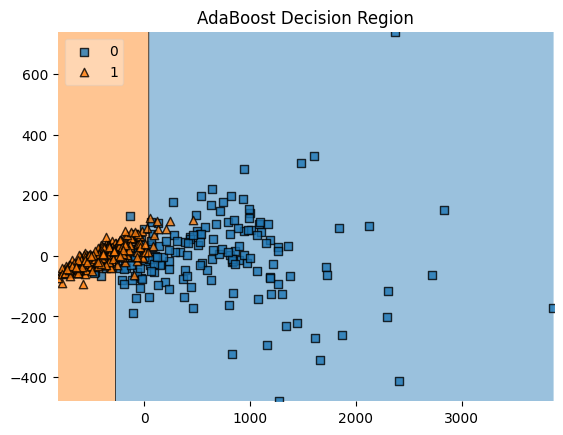

In [156]:
plot_decision_regions(X_train,y_train,clf=model,legend=2)
# 5. Beautify plot
plt.title("AdaBoost Decision Region")
plt.show()

Param_grid is always defined as dictionary or list of dictionaries

In [157]:
from sklearn.model_selection import GridSearchCV

In [164]:
grid= {
    'n_estimators':[50,100,150,200,500],
    'learning_rate':[0.0001,0.001,0.01,0.1,1],
    'algorithm':['SAMME','SAMME.R']
}


In [165]:
grid_search=GridSearchCV(model,param_grid=grid,n_jobs=-1,cv=10,scoring='accuracy')

In [166]:
result= grid_search.fit(X_train,y_train)
print(result.best_score_,result.best_params_)

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
200 fits failed out of a total of 400.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
200 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.11/dist-packages/sklearn/util

0.9295652173913043 {'algorithm': 'SAMME', 'learning_rate': 1, 'n_estimators': 150}


In [162]:
from sklearn.model_selection import cross_val_score

  # Calculate training accuracy
train_accuracy = result.score(X_train, y_train)

  # Calculate cross-validation accuracy (validation accuracy)
cv_accuracy = result.best_score_

print("Training Accuracy:", train_accuracy)
print("Cross-Validation Accuracy:", cv_accuracy)

Training Accuracy: 0.9538461538461539
Cross-Validation Accuracy: 0.9295652173913043


In [163]:
print("Best Hyperparameters:", result.best_params_)

Best Hyperparameters: {'algorithm': 'SAMME', 'learning_rate': 1, 'n_estimators': 150}
